<a href="https://colab.research.google.com/github/Minh-Quan-hub/build-ai-agents-and-chatbots-118s/blob/AgenticAI_in_Marketing/ad_optimization_agent_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **1. Ad Optimization Agent**

In [9]:
SYSTEM_PROMPT = """You review daily ad-budget shifts to improve conversions across Search, Social, and Display.
The host supplies aggregate performance from the three completed days before the decision and a safe proposed allocation.
Approve the exact proposal when the recent conversions per dollar, CTR, CVR, and CPA support it; otherwise hold yesterday's budget.
Give one concise factual reason. Do not invent metrics, change dollar amounts, include customer information, or write ad copy.
The host enforces the fixed daily total, 10% minimum channel share, 20% daily change limit, and 10% transfer limit.
"""

### **2. Setup and CSV Upload**

In [10]:
%pip -q install langgraph openai

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import TypedDict
from pydantic import BaseModel
from openai import OpenAI
from langgraph.graph import StateGraph, END
from google.colab import files, userdata

DAILY_BUDGET = 300.0
USE_LLM = True
MODEL = "gpt-4o-mini"

uploaded = files.upload()
data = pd.read_csv(next(iter(uploaded)), parse_dates=["date"]).sort_values(["date", "channel"])
channels = tuple(sorted(data["channel"].unique()))
client = OpenAI(api_key=userdata.get("OPENAI_API_KEY")) if USE_LLM else None
print(f"Loaded {len(data)} rows for {len(channels)} channels and {data.date.nunique()} days.")

Saving ad_performance_mock.csv to ad_performance_mock (1).csv
Loaded 63 rows for 3 channels and 21 days.


### **3. Performance Metrics and Budget Tool**

In [11]:
def calculate_metrics(rows):
    totals = rows.groupby("channel")[["spend", "impressions", "clicks", "conversions"]].sum()
    totals["ctr"] = totals.clicks / totals.impressions.replace(0, np.nan)
    totals["cvr"] = totals.conversions / totals.clicks.replace(0, np.nan)
    totals["cpa"] = totals.spend / totals.conversions.replace(0, np.nan)
    totals["conversions_per_dollar"] = totals.conversions / totals.spend
    return totals


def decide_budget_shift(previous, recent):
    rates = calculate_metrics(recent)["conversions_per_dollar"]
    winner = rates.idxmax()
    proposed = previous.copy()
    reason = "Hold: recent performance does not support an eligible shift."

    for donor in rates.sort_values().index:
        if donor == winner or rates[winner] <= 1.05 * rates[donor]:
            continue
        amount = round(min(0.10 * DAILY_BUDGET, 0.20 * previous[winner],
                           0.20 * previous[donor], previous[donor] - 0.10 * DAILY_BUDGET), 2)
        if amount > 0:
            proposed[winner] = round(previous[winner] + amount, 2)
            proposed[donor] = round(previous[donor] - amount, 2)
            reason = (f"Move ${amount:.2f} from {donor} to {winner}: "
                      f"recent conversions/$ {rates[winner]:.4f} vs {rates[donor]:.4f}.")
            break
    return proposed, reason

### **4. LangGraph Agent and Daily Decisions**

In [12]:
class AgentState(TypedDict, total=False):
    date: pd.Timestamp
    day_number: int
    previous: dict
    recent: pd.DataFrame
    budget: dict
    reason: str


class BudgetReview(BaseModel):
    approve: bool
    reason: str


def fetch_campaign_data(state: AgentState):
    prior = data[data.date < state["date"]]
    recent_days = sorted(prior.date.unique())[-3:]
    return {"recent": prior[prior.date.isin(recent_days)]}


def agent_reasoning(state: AgentState):
    if state["day_number"] < 3:
        return {"budget": state["previous"], "reason": "Equal-split learning period."}

    proposed, reason = decide_budget_shift(state["previous"], state["recent"])
    if USE_LLM and proposed != state["previous"]:
        evidence = calculate_metrics(state["recent"]).reset_index().to_json(orient="records")
        response = client.responses.parse(
            model=MODEL,
            input=[{"role": "system", "content": SYSTEM_PROMPT},
                   {"role": "user", "content": json.dumps({"date": str(state["date"].date()),
                    "previous": state["previous"], "proposed": proposed, "recent_metrics": json.loads(evidence)})}],
            text_format=BudgetReview,
            max_output_tokens=180,
            store=False,
        )
        review = response.output_parsed
        if review.approve:
            reason += " API review: " + review.reason
        else:
            proposed = state["previous"]
            reason = "Hold after API review: " + review.reason
    return {"budget": proposed, "reason": reason}


def execute_tools(state: AgentState):
    return {"budget": state["budget"]}  # Simulated allocation; no ad-platform write.


workflow = StateGraph(AgentState)
workflow.add_node("fetch_campaign_data", fetch_campaign_data)
workflow.add_node("agent_reasoning", agent_reasoning)
workflow.add_node("execute_tools", execute_tools)
workflow.set_entry_point("fetch_campaign_data")
workflow.add_edge("fetch_campaign_data", "agent_reasoning")
workflow.add_edge("agent_reasoning", "execute_tools")
workflow.add_edge("execute_tools", END)
app = workflow.compile()

previous = {channel: round(DAILY_BUDGET / len(channels), 2) for channel in channels}
previous[channels[-1]] = round(DAILY_BUDGET - sum(previous[ch] for ch in channels[:-1]), 2)
log = []
for day_number, date in enumerate(sorted(data.date.unique())):
    result = app.invoke({"date": pd.Timestamp(date), "day_number": day_number, "previous": previous})
    current = result["budget"]
    for channel in channels:
        log.append({"date": date, "channel": channel,
                    "previous_budget": previous[channel], "budget": current[channel],
                    "shift": round(current[channel] - previous[channel], 2), "reason": result["reason"]})
    previous = current

decisions = pd.DataFrame(log)
print(decisions.pivot(index="date", columns="channel", values="budget").round(2).to_string())
print("\nDecision log:")
print(decisions[decisions["shift"] != 0].head(9).to_string(index=False))

channel     Display  Search  Social
date                               
2026-09-01    100.0   100.0   100.0
2026-09-02    100.0   100.0   100.0
2026-09-03    100.0   100.0   100.0
2026-09-04    100.0   100.0   100.0
2026-09-05    100.0   100.0   100.0
2026-09-06    100.0   100.0   100.0
2026-09-07    100.0   100.0   100.0
2026-09-08    100.0   100.0   100.0
2026-09-09    100.0   100.0   100.0
2026-09-10    100.0   100.0   100.0
2026-09-11    100.0   100.0   100.0
2026-09-12    100.0   100.0   100.0
2026-09-13    100.0   100.0   100.0
2026-09-14    100.0   100.0   100.0
2026-09-15    100.0   100.0   100.0
2026-09-16    100.0   100.0   100.0
2026-09-17    100.0   100.0   100.0
2026-09-18    100.0   100.0   100.0
2026-09-19    100.0   100.0   100.0
2026-09-20    100.0   100.0   100.0
2026-09-21    100.0   100.0   100.0

Decision log:
Empty DataFrame
Columns: [date, channel, previous_budget, budget, shift, reason]
Index: []


### **5. Evaluation and Exports**


Equal-spend comparison (modeled, assuming outcomes scale linearly with spend):
             budget  impressions  clicks  conversions    ctr    cvr     cpa
policy                                                                     
Agent        6300.0     110385.0  4938.0        412.0  0.045  0.083  15.291
Equal split  6300.0     110385.0  4938.0        412.0  0.045  0.083  15.291


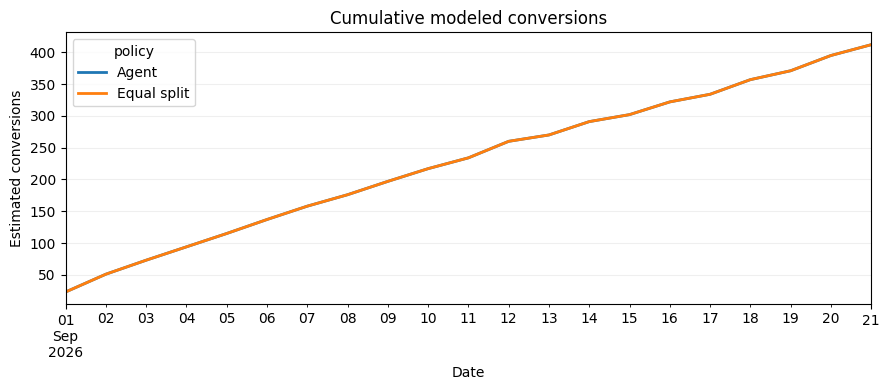

In [15]:
joined = data.merge(decisions[["date", "channel", "budget"]], on=["date", "channel"])
results = []
for policy, budgets in [("Agent", joined.budget),
                        ("Equal split", pd.Series(DAILY_BUDGET / len(channels), index=joined.index))]:
    scale = budgets / joined.spend
    estimated = joined[["date", "channel"]].copy()
    estimated["policy"] = policy
    estimated["budget"] = budgets
    for metric in ("impressions", "clicks", "conversions"):
        estimated[metric] = joined[metric] * scale
    results.append(estimated)

detail = pd.concat(results, ignore_index=True)
comparison = detail.groupby("policy")[["budget", "impressions", "clicks", "conversions"]].sum()
comparison["ctr"] = comparison.clicks / comparison.impressions
comparison["cvr"] = comparison.conversions / comparison.clicks
comparison["cpa"] = comparison.budget / comparison.conversions
print("\nEqual-spend comparison (modeled, assuming outcomes scale linearly with spend):")
print(comparison.round(3).to_string())

daily = detail.groupby(["date", "policy"]).conversions.sum().unstack()
ax = daily.cumsum().plot(figsize=(9, 4), linewidth=2)
ax.set(title="Cumulative modeled conversions", xlabel="Date", ylabel="Estimated conversions")
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

decisions.to_csv("ad_agent_decision_log.csv", index=False)
comparison.to_csv("ad_agent_evaluation.csv")